In [1]:
using LinearAlgebra
using DifferentialEquations, Plots
using BenchmarkTools
using HypothesisTests
default(grid=false,legend=false, size=(400,320), dpi=300, tickfontsize=16, lw=2, lc=:gray, labelfontsize=16, tickdir=:out, fontfamily="Arial", legendfontsize=13, markercolor=:indianred)

mydir = "../helper/"
include(mydir * "base.jl")
include(mydir * "optimization.jl")
include(mydir * "misc.jl")
include(mydir * "myplot.jl")

plot_histogram (generic function with 1 method)

### Load data

In [2]:
using DelimitedFiles
# INSERT YOUR OWN DATA DIRECTORY AND FILENAME HERE
# E. coli MG1655 (CGSC 6300)/20090131/xy01c1/ch1_cell0.dat
data_dir = "/Volumes/Chenyi/MIT/research/Cell_growth/data/CurrBiol10/E_coli_MG1655/"
DT = 1/60; # convert to hours
DL = 0.0645; # convert to um

In [3]:
# # manual selection

# data_date = "20090131/"
# data_fov = "xy14c1/"
# filename_all = readdir(data_dir*data_date*data_fov);
# select_cache = filename_all[ contains.(filename_all, "_cell0.dat") ]

# idx=1
# tab_cache=readdlm(data_dir * data_date * data_fov * select_cache[idx]);
# varnames = convert(Vector{String}, tab_cache[1,:]);
# tt = tab_cache[2:end,findfirst(varnames .== "index")] * DT;
# LL = tab_cache[2:end,findfirst(varnames .== "length")] * DL;
# data_date * data_fov * select_cache[idx]
# tmp = [(0,50.0)]
# pp = plot(tt, LL, size=(1500,300),bottommargin=7Plots.mm, leftmargin=5Plots.mm)
# for i in eachindex(tmp)
#     plot!(pp, tt[ (tt.>tmp[i][1]) .& (tt .< tmp[i][2]) ], LL[(tt.>tmp[i][1]) .& (tt .< tmp[i][2])],lc=:indianred)
# end

In [5]:
# INSERT SELECTED FILES AND TIME WINDOWS HERE.

select_filename =[
    "20090131/xy01c1/ch0_cell0.dat",
    "20090131/xy01c1/ch1_cell0.dat",
    "20090131/xy01c1/ch2_cell0.dat",
    "20090131/xy01c1/ch3_cell0.dat",
    "20090131/xy01c1/ch4_cell0.dat",
    "20090131/xy01c1/ch5_cell0.dat",
    "20090131/xy01c1/ch6_cell0.dat",
    "20090131/xy02c1/ch0_cell0.dat",
    "20090131/xy03c1/ch0_cell0.dat",
    "20090131/xy04c1/ch0_cell0.dat",
    "20090131/xy04c1/ch1_cell0.dat",
    "20090131/xy05c1/ch0_cell0.dat",
    "20090131/xy05c1/ch1_cell0.dat",
    "20090131/xy05c1/ch2_cell0.dat",
    "20090131/xy05c1/ch3_cell0.dat",
    "20090131/xy06c1/ch0_cell0.dat",
    "20090131/xy06c1/ch1_cell0.dat",
    "20090131/xy06c1/ch2_cell0.dat",
    "20090131/xy06c1/ch3_cell0.dat",
    "20090131/xy07c1/ch0_cell0.dat",
    "20090131/xy07c1/ch1_cell0.dat",
    "20090131/xy07c1/ch2_cell0.dat",
    "20090131/xy07c1/ch3_cell0.dat",
    "20090131/xy07c1/ch4_cell0.dat",
    "20090131/xy07c1/ch5_cell0.dat",
    "20090131/xy08c1/ch0_cell0.dat",
    "20090131/xy08c1/ch1_cell0.dat",
    "20090131/xy08c1/ch2_cell0.dat",
    "20090131/xy08c1/ch3_cell0.dat",
    "20090131/xy08c1/ch4_cell0.dat",
    "20090131/xy09c1/ch0_cell0.dat",
    "20090131/xy09c1/ch1_cell0.dat",
    "20090131/xy09c1/ch2_cell0.dat",
    "20090131/xy09c1/ch3_cell0.dat",
    "20090131/xy10c1/ch0_cell0.dat",
    "20090131/xy10c1/ch1_cell0.dat",
    "20090131/xy10c1/ch2_cell0.dat",
    "20090131/xy11c1/ch0_cell0.dat",
    "20090131/xy12c1/ch0_cell0.dat",
    "20090131/xy12c1/ch1_cell0.dat",
    "20090131/xy12c1/ch2_cell0.dat",
    "20090131/xy12c1/ch3_cell0.dat",
    "20090131/xy12c1/ch4_cell0.dat",
    "20090131/xy12c1/ch5_cell0.dat",
    "20090131/xy12c1/ch6_cell0.dat",
    "20090131/xy12c1/ch7_cell0.dat",
    "20090131/xy13c1/ch0_cell0.dat",
    "20090131/xy13c1/ch1_cell0.dat",
    "20090131/xy13c1/ch2_cell0.dat",
    "20090131/xy14c1/ch0_cell0.dat",
]

select_time_all = [
    [(0.0, 11.0), (12.6, 26.8), (33.3, 46.8), (51.6, 60.8)],
    [(0.0, 20.8), (21.6, 34.3)],
    [(0.0, 24.0),(27.0,46.0)],
    [(52.,65.0)],
    [(58.,65.0)],
    [(51.5,64.0)],
    [(53.0,64.3)],
    [(0.0,18.55), (19.5,31.0)],
    [(0.0,29.5)],
    [(0.0,16.0), (21.0, 43.0)],
    [(0.0,4.0), (5.0, 21.8), (26.5,46.0)],
    [(0.0,8.5), (9.5, 32.8)],
    [(0.0,25.5), (26.2, 32.5)],
    [(0.0,20.1)],
    [(55.0,65.0)],
    [(0.0,13.5),(18.5,34.0)],
    [(0.0,27.9)],
    [(0.0,19.0),(22.5,34.5)],
    [(48.0,65.0)],
    [(0.0,14.2),(15.5,30.5)],
    [(0.0,12.5),(13.3,19.2),(22.0,48.0),(50.0,60.5)],
    [(1.3,22.0),(25.5,49.8),(52.5,65.0)],
    [(37.0,54.0)],
    [(40.2,61.0)],
    [(50.0,64.5)],
    [(0.0,40.5),(41.8,55.2)],
    [(0.0,39.5)],
    [(0.0, 21.0),(24.2,40.0)],
    [(48.0,65.0)],
    [(62.0,65.0)],
    [(4.5, 34.5), (36.5,56.0)],
    [(0.0,40.0)],
    [(0.0,4.3),(5.3,13.0),(13.5,44.0),(46.0,61.6)],
    [(58.0,65.0)],
    [(2.2,22.0)],
    [(0.0,18.5),(37.0,54.0)],
    [(58.0,65.0)],
    [(1.3,38.0)],
    [(0.,24.0),(31.0,39.4),(42.3,60.0)],
    [(41.5,65.0)],
    [(43.0,64.5)],
    [(43.6,65.0)],
    [(50.0,65.0)],
    [(44.0,65.0)],
    [(50.0,65.0)],
    [(50.0,65.0)],
    [(0.1,7.0),(8.2,43.4)],
    [(39.0,44.8),(50.4,63.6)],
    [(53.5,60.0)],
    [(0.0,50.0)]
]

# annotate
Lobs_ = []
tobs_ = []
for idx in eachindex(select_filename)
    tab = readdlm(data_dir * select_filename[idx]);
    varnames = convert(Vector{String}, tab[1,:]);
    tobs = tab[2:end,findfirst(varnames .== "index")] * DT;
    Lobs = tab[2:end,findfirst(varnames .== "length")] * DL;
    Lobs_idx, tobs_idx = filter_exp_traj(Lobs, tobs; select_time = select_time_all[idx] );
    Lobs_ = vcat(Lobs_, Lobs_idx)
    tobs_ = vcat(tobs_, tobs_idx)
end
Lobs_ = convert.(Vector{Float64}, Lobs_);
tobs_ = convert.(Vector{Float64}, tobs_);


In [6]:
(size(select_filename) == size(select_time_all)) && (@show size(select_filename);)


size(select_filename) = (50,)


(50,)

In [7]:
isdiv_, dtobs_ = annotate_exp_traj(Lobs_, tobs_);

In [8]:
sum(sum.(isdiv_))

3916

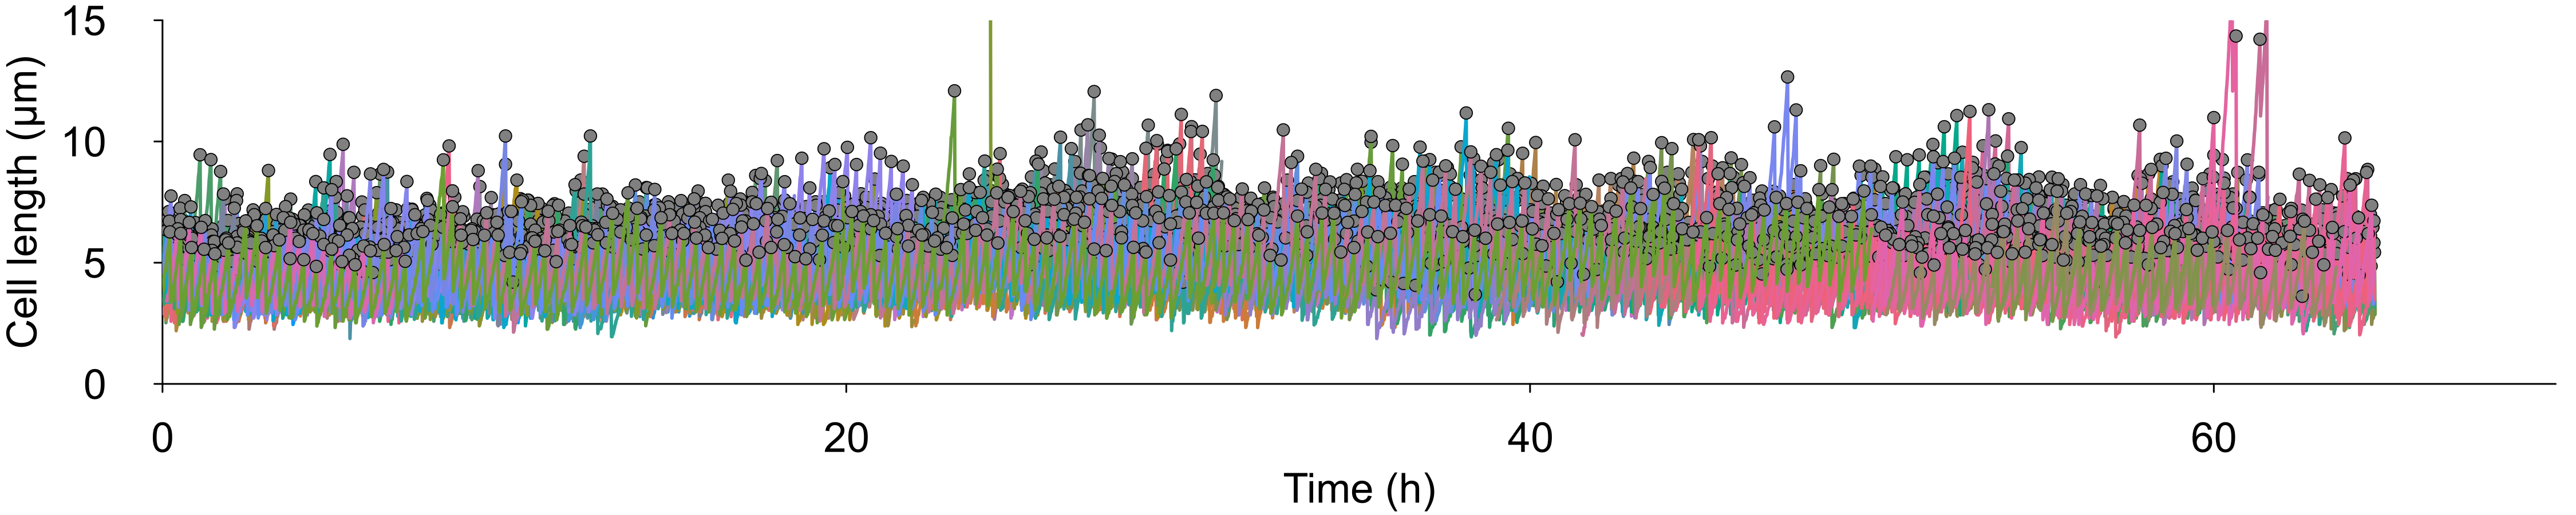

In [9]:
p_traj_obs = plot(; size=(1500,300), xlim=(0,70), ylim=(0,15), xtick=collect(0:20:80), ytick=collect(0:5:15), bottommargin=12Plots.mm,  leftmargin=9Plots.mm, xlabel="Time (h)", ylabel="Cell length (μm)")
linecolor_ = palette(:default, length(Lobs_) )
for i in eachindex(Lobs_)
    plot!(p_traj_obs, tobs_[i], Lobs_[i], lc=linecolor_[i])
    scatter!(p_traj_obs, tobs_[i][isdiv_[i]], Lobs_[i][isdiv_[i]], markercolor=:gray)
end
p_traj_obs

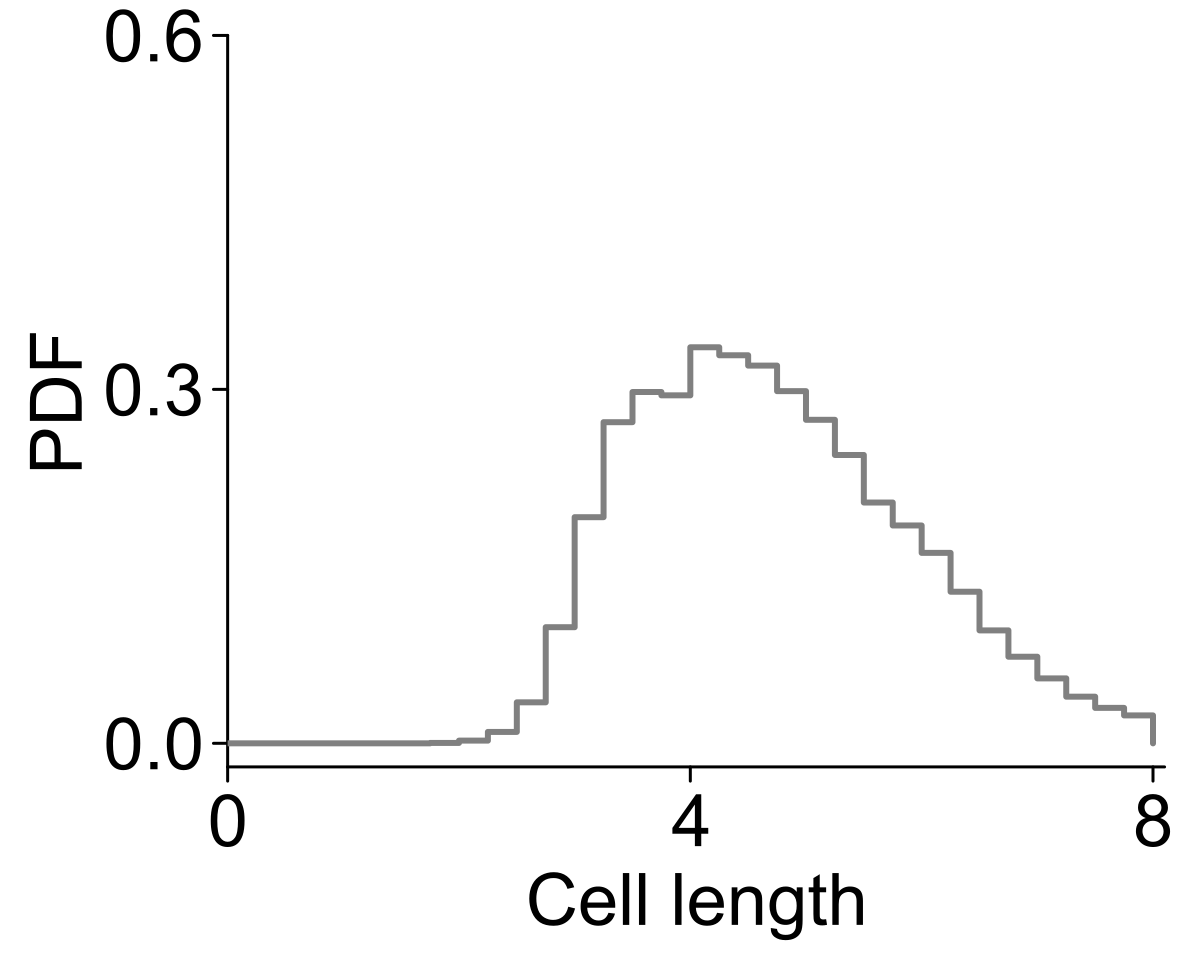

In [10]:
p1 = plot(;xlim=(0,8.1), xtick=[0,4,8],ylim=(-0.02,0.6),ytick=[0,0.3,0.6])
stephist!( p1, vcat(Lobs_...), bins=collect(0:0.25:8), normalize=:pdf, xlabel="Cell length", ylabel="PDF")


### Looking at joint probability

In [11]:
using StatsBase
hedges = collect(3:0.35:10.0);
hbins = 0.5*( hedges[1:end-1] + hedges[2:end] )
dhedges = mean( diff(hedges) );

h1_obs = fit(Histogram, vcat( [Lobs_[i][isdiv_[i]] for i in eachindex(Lobs_) ]...), hedges)
h2_obs = fit(Histogram, (vcat( [Lobs_[i][isdiv_[i]][1:end-1] for i in eachindex(Lobs_) ]...), vcat( [Lobs_[i][isdiv_[i]][2:end] for i in eachindex(Lobs_) ]...) ), (hedges,hedges));


In [12]:
# obs
h1_obs_normalize = h1_obs.weights / sum(h1_obs.weights) / dhedges
h2_obs_normalize = h2_obs.weights / sum(h2_obs.weights) / dhedges^2

svd_h1_obs = svd(h1_obs_normalize * h1_obs_normalize');
svd_h2_obs = svd(h2_obs_normalize);

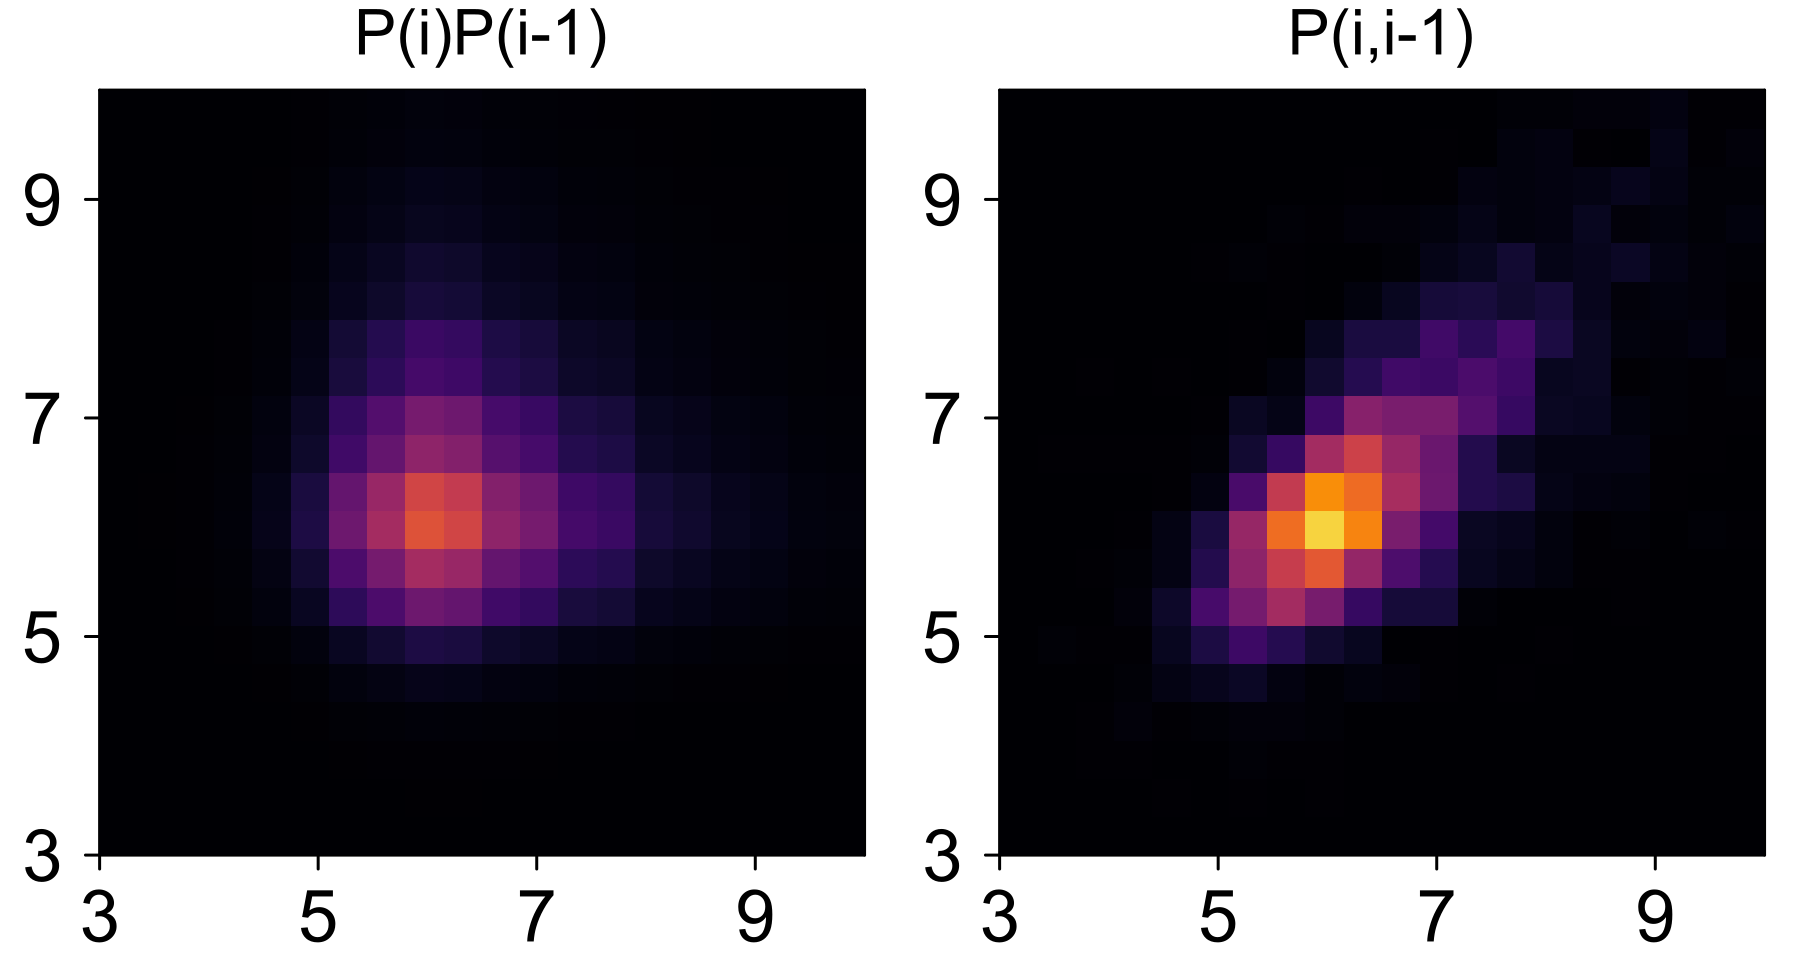

In [13]:
p_h1_obs = plot(; aspect_ratio=1, framestyle=:box, xlim=(hedges[1],hedges[end]), ylim=(hedges[1],hedges[end]), xtick=collect(3:2:10), ytick=collect(3:2:10), title="P(i)P(i-1)" )
heatmap!( p_h1_obs, hbins, hbins, h1_obs_normalize * h1_obs_normalize', clim=(0,0.4)) 

p_h2_obs = plot(; aspect_ratio=1, framestyle=:box, xlim=(hedges[1],hedges[end]), ylim=(hedges[1],hedges[end]), xtick=collect(3:2:10), ytick=collect(3:2:10), title="P(i,i-1)" )
heatmap!( p_h2_obs, hbins, hbins, h2_obs_normalize, clim=(0,0.4)) 
ll=@layout [a b]
plot(p_h1_obs, p_h2_obs, layout = ll, size=(600,320), dpi=300)
# savefig("heatmap_exp.png")

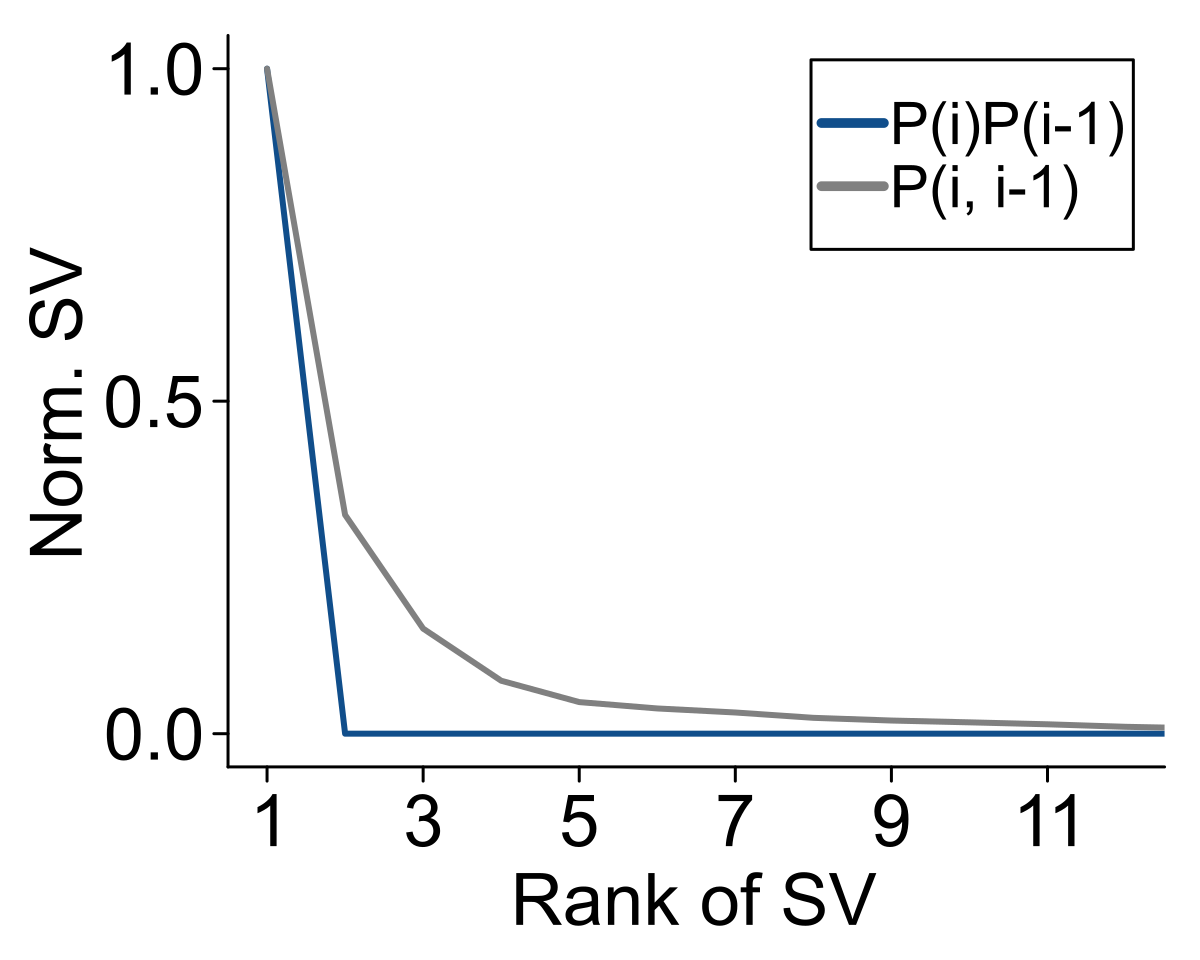

In [14]:
p_S_obs = plot(; xlim=[0.5,12.5], ylim=[-0.05,1.05], ytick=[0,0.5,1], xtick=collect(1:2:13), xlabel="Rank of SV", ylabel = "Norm. SV", legend=true)
plot!( p_S_obs, svd_h1_obs.S ./ svd_h1_obs.S[1], lc=:dodgerblue4, label="P(i)P(i-1)" )
plot!( p_S_obs, svd_h2_obs.S ./ svd_h2_obs.S[1],  label="P(i, i-1)" )
# savefig("svd_exp.pdf")

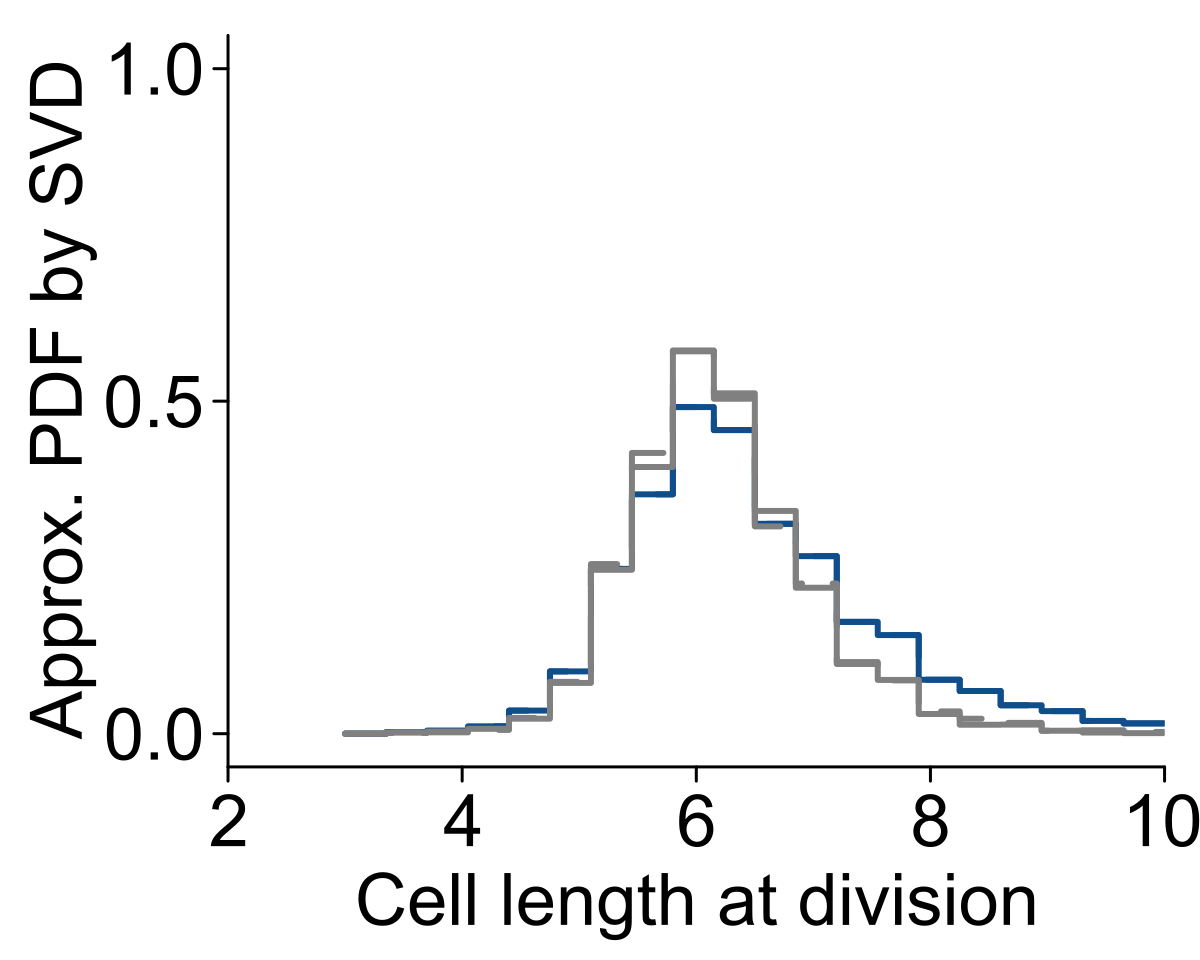

In [15]:
yU_h1_obs = svd_h1_obs.U[:,1] * sqrt(svd_h1_obs.S[1])
yV_h1_obs = svd_h1_obs.V[:,1] * sqrt(svd_h1_obs.S[1])

yU_h2_obs = svd_h2_obs.U[:,1] * sqrt(svd_h2_obs.S[1])
yV_h2_obs = svd_h2_obs.V[:,1] * sqrt(svd_h2_obs.S[1])

p_UV_obs = plot(; ylim=(-0.05,1.05), xlim=(2,10), xtick=collect(2:2:10), ytick=collect(0:0.5:1), xlabel="Cell length at division", ylabel="Approx. PDF by SVD")
plot_histogram!(p_UV_obs, hedges, abs.(yU_h1_obs); lc=:dodgerblue4)
plot_histogram!(p_UV_obs, hedges, abs.(yV_h1_obs); ls=:dash, lc=:dodgerblue4)
plot_histogram!(p_UV_obs, hedges, abs.(yU_h2_obs))
plot_histogram!(p_UV_obs, hedges, abs.(yV_h2_obs); ls=:dash)
# plot_histogram!(p_UV_obs, hedges, h1_obs_normalize, lc=:black)
p_UV_obs

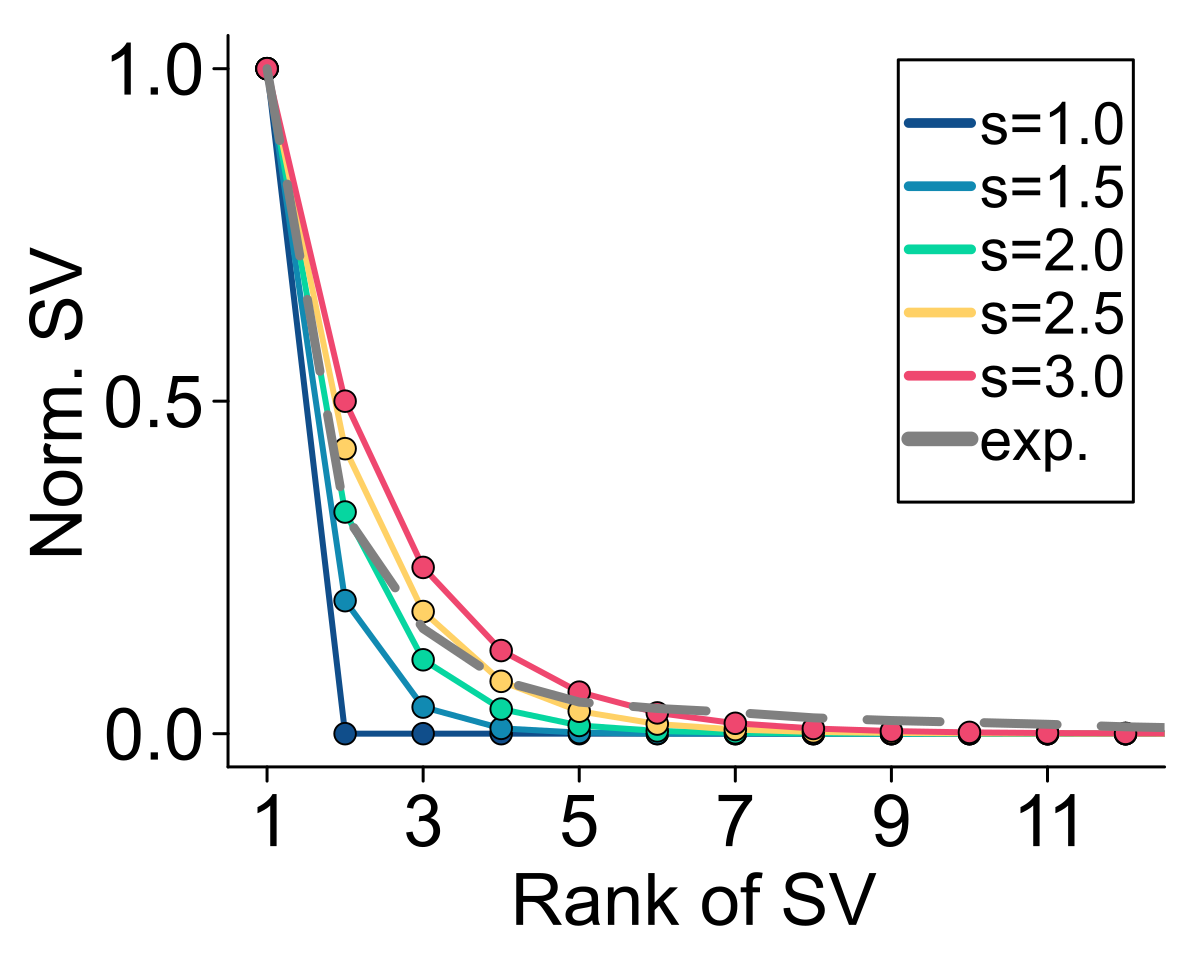

In [17]:
A = 2.5
μx = 6.5
μy = 6.5
p_gs = plot(;xlim=[0.5,12.5], ylim=[-0.05,1.05], ytick=[0,0.5,1], xtick=collect(1:2:13), xlabel="Rank of SV", ylabel = "Norm. SV", legend=true)

B_array = [1.0, 1.5, 2.0, 2.5, 3.0];
C_array = [:dodgerblue4,colorant"#118AB2",colorant"#06D6A0",colorant"#FFD166",colorant"#EF476F"]

p_hist2d = Vector(undef, length(B_array))
for i = 1:length(B_array)
    p_hist2d[i] = plot(; aspect_ratio=1, framestyle=:box, xlim=(hedges[1],hedges[end]), ylim=(hedges[1],hedges[end]), xtick=collect(3:2:10), ytick=collect(3:2:10), title="s=$(B_array[i])")
end

u1(x::T,σ::T) where T = exp(-x^2/2/σ^2)/sqrt(π^(1/2)*σ)
u2(x::T,σ::T) where T = x*exp(-x^2/2/σ^2)/sqrt(π^(1/2)*σ^3/2)
u3(x::T,σ::T) where T = x^2*exp(-x^2/2/σ^2) /sqrt(π^(1/2)*σ^5/2) - u1(x,σ) * sqrt(1/2)
u4(x::T,σ::T) where T = x^3*exp(-x^2/2/σ^2)/sqrt(3*π^(1/2)*σ^7/4) - u2(x,σ) * sqrt(3/2)

p_svd_u = Vector(undef, 4)
for i = 1:4
    p_svd_u[i] = plot(; xlim=(hedges[1],hedges[end]), xtick=collect(3:2:10), title="rank=$i", legend=true, ytick=collect(-1.0:0.2:1.0))
end

nn = collect(1:12);
xx = collect(hedges[1]:0.01:hedges[end]);

for i in eachindex(B_array)
    B = B_array[i]
    s₊ = sqrt(A*B^2/(1+B^2))
    s₋ = sqrt(A/(1+B^2))
    σ = sqrt(s₊ * s₋ / 2)
    
    h2_gs = exp.( -0.5*( (hbins .+ hbins' .- μx .- μy).^2 ./ s₊^2 .+ (hbins .- hbins').^2 ./ s₋^2 ) )
    h2_gs_normalize=  h2_gs / sum(h2_gs) / dhedges^2
    svd_gs = svd(h2_gs_normalize);
    # plot sv
    plot!( p_gs, svd_gs.S ./ svd_gs.S[1], label="s=$B", lc=C_array[i] )
    scatter!(p_gs, nn, ((B-1)/(B+1)).^(nn .- 1),mc=C_array[i], label=false)
    # plot heatmap
    heatmap!(p_hist2d[i], hbins, hbins, h2_gs_normalize, clim=(0,0.4), xlim=(hedges[1],hedges[end]), ylim=(hedges[1],hedges[end]) ) 
    # plot u 
    (i==1) && (continue)
    plot_histogram!(p_svd_u[1], hedges, svd_gs.U[:,1]*sign(svd_gs.U[3,2]), lc=C_array[i], label="s=$B", ylim=(-0.05,0.6))
    plot!(p_svd_u[1], xx, sqrt(dhedges) * u1.(xx .- μx,σ), lc=C_array[i],label=false)

    plot_histogram!(p_svd_u[2], hedges, -svd_gs.U[:,2]*sign(svd_gs.U[3,2]), lc=C_array[i], label=false, ylim=(-0.5,0.5))
    plot!(p_svd_u[2], xx, sqrt(dhedges) * u2.(xx .- μx,σ), lc=C_array[i],label=false)

    plot_histogram!(p_svd_u[3], hedges, svd_gs.U[:,3]*sign(svd_gs.U[3,3]), lc=C_array[i], label=false, ylim=(-0.5,0.5))
    plot!(p_svd_u[3], xx, sqrt(dhedges) * u3.(xx .- μx,σ), lc=C_array[i],label=false)

    plot_histogram!(p_svd_u[4], hedges, -svd_gs.U[:,4]*sign(svd_gs.U[3,4]), lc=C_array[i], label=false, ylim=(-0.5,0.5))
    plot!(p_svd_u[4], xx, sqrt(dhedges) * u4.(xx .- μx,σ), lc=C_array[i],label=false)
end
# p_gs
plot!( p_gs, svd_h2_obs.S ./ svd_h2_obs.S[1],  label="exp.",lw=3, ls=:dash)


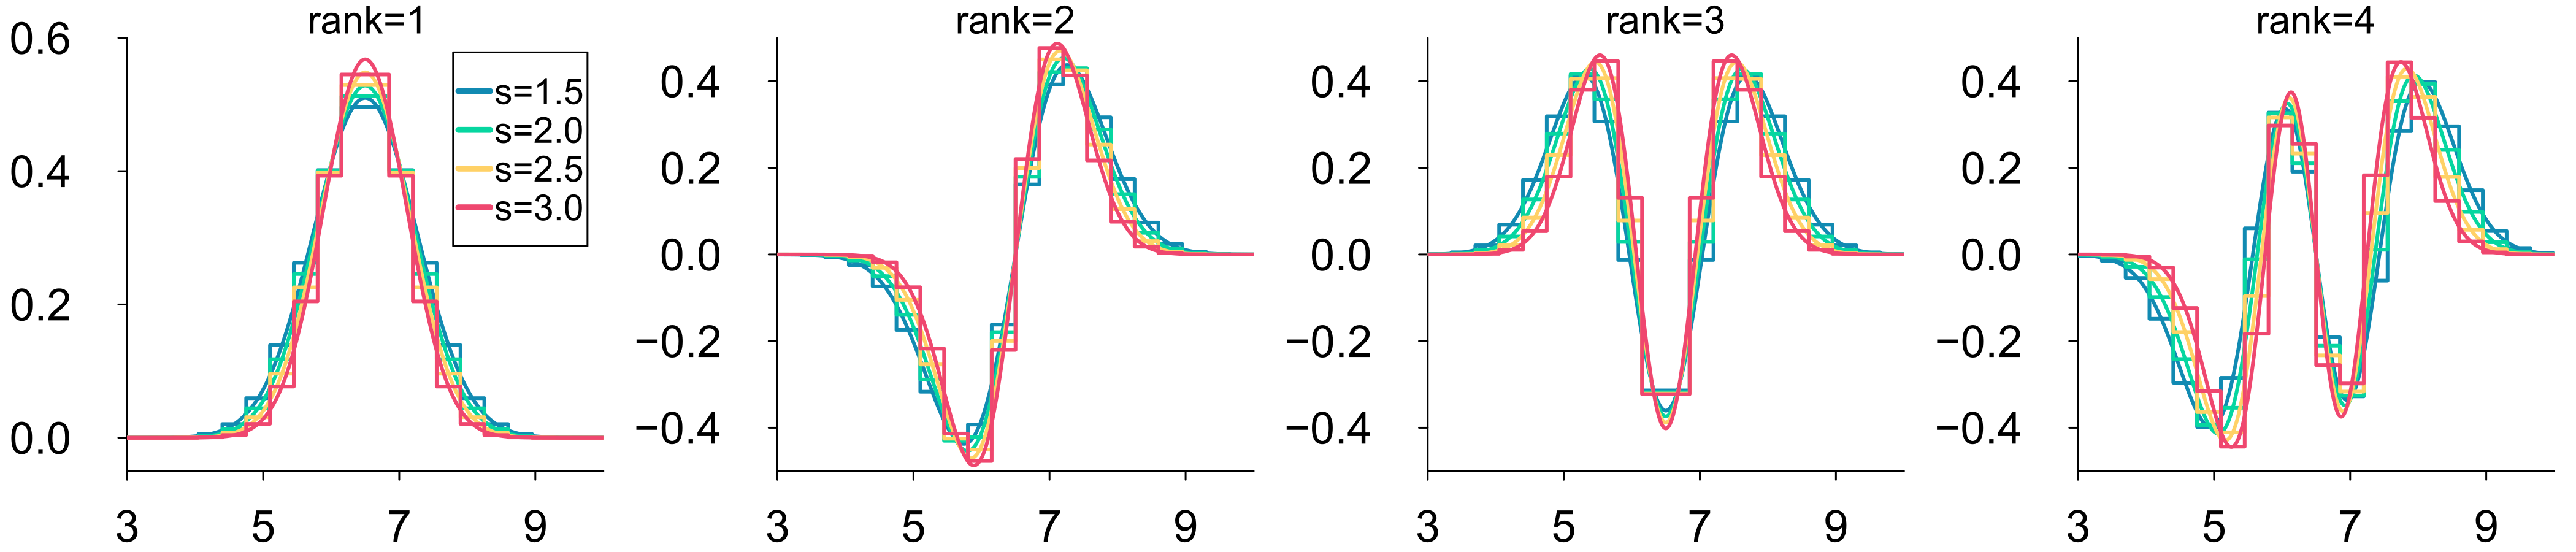

In [18]:
p_u_sum = plot(p_svd_u..., layout=@layout [a b c d] ;size=(1400,300), bottommargin=6Plots.mm, leftmargin=3Plots.mm)
# savefig("U_n_Gaussian.pdf")

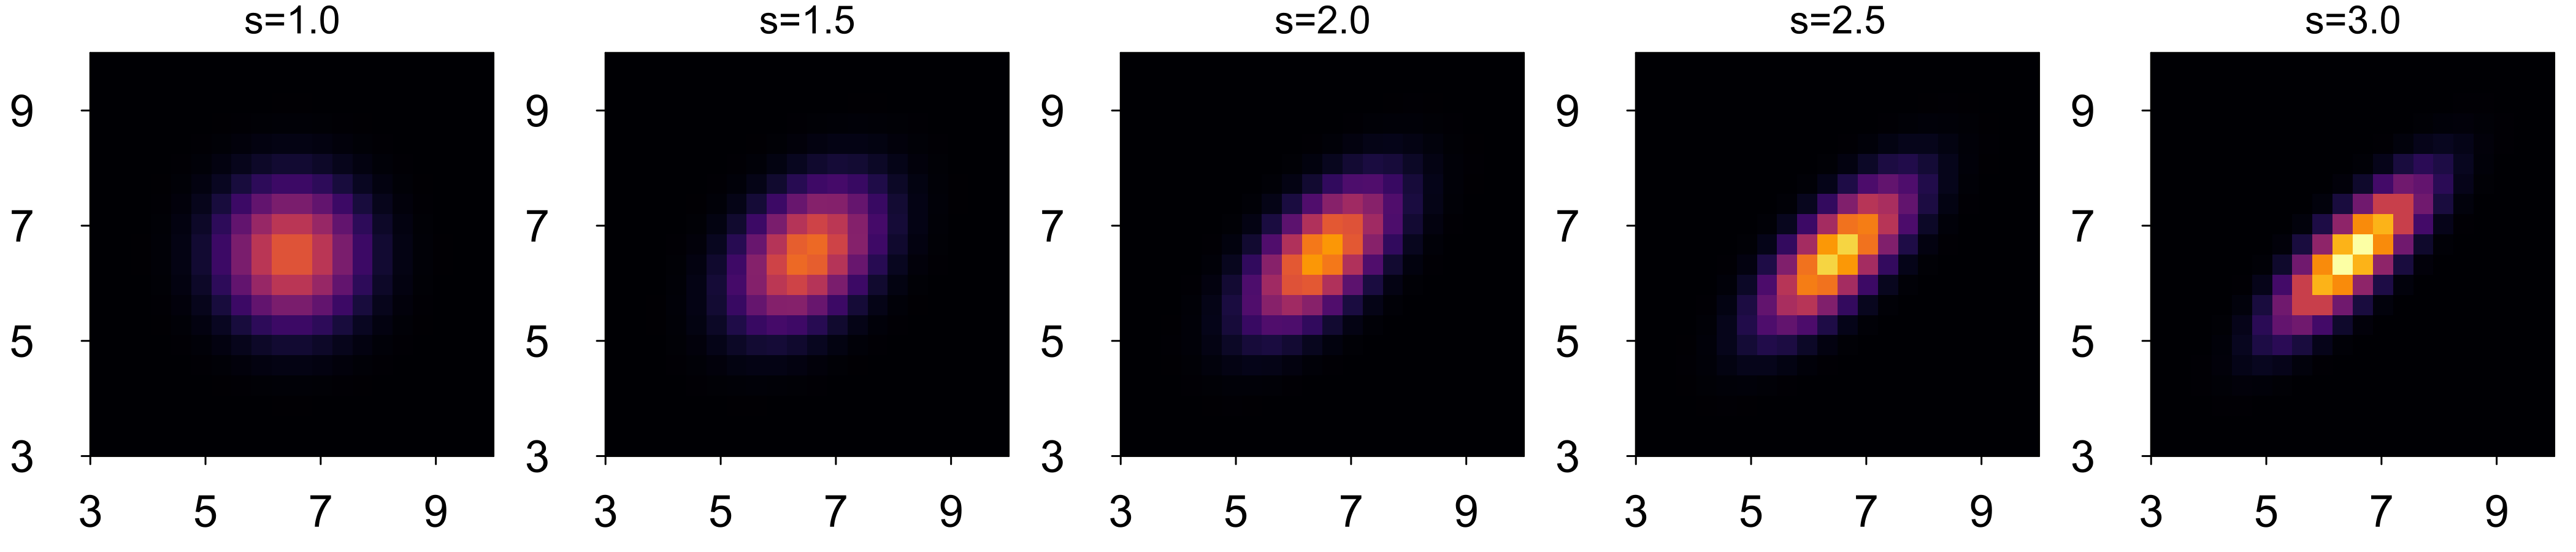

In [19]:
p_hist2d_sum = plot(p_hist2d..., layout=@layout [a b c d e] ;size=(1400,300), bottommargin=6Plots.mm, leftmargin=3Plots.mm, dpi=300)
# savefig("P_Gaussian.png")

In [20]:
# savefig(p_gs, "SV_Gaussian.pdf")